
> **Noise-floor version.** Copy of `nogse_d0_pixel_maps.ipynb` with one addition: with `NOISE_FLOOR = 'plateau'` the magnitude noise floor is removed from every pixel curve and from the ROI curve before fitting, $a=\sqrt{\max(s^2-c^2,0)}/\sqrt{1-c^2}$ with $c=F/S_0$ (`docs/papers/metrics_note_detailed.pdf`, Section 3, step 4). $F$ is a **floor map**: the mean, pixel by pixel, of the volumes whose predicted free-water attenuation is below `PLATEAU_MAX_SIGNAL` (Hahn, $T=65$ ms, $G\ge49$ mT/m), smoothed inside the mask. In free water nothing survives there, so what remains is the floor. The section "Noise floor" also measures $\sigma$ from the two b0 volumes of the raw images and reports $\kappa=F/\sigma$ and the number of effective channels it implies. With `NOISE_FLOOR = None` this notebook reproduces the original. Outputs go to `results/<MODEL>_noise_floor/`. New cells are in English; the original cells are unchanged except where marked `# noise floor`.

# Mapas de $D_0$ píxel a píxel con el modelo NOGSE libre

En vez de ajustar la señal media de un ROI, se ajusta $D_0$ en **cada píxel** de la máscara y se arma un mapa. Es el mismo ajuste de un parámetro que `nogse_fits_rectangular_lobes.ipynb` / `nogse_fits_trapezoidal_lobes.ipynb` ($M_0=1$ fijo, error cuadrático medio en escala lineal, optimizando $\ln D_0$ entre cotas), aplicado a la curva $S(G)/S_0$ de cada píxel:

$$M_{píxel}(G) = \frac{S_{píxel}(G)}{S_{0,píxel}} = e^{-k\,G^2\,D_0},\qquad S_{0,píxel} = \text{media de los b0 de la misma serie}.$$

Se ajustan Hahn y CPMG (una curva por serie y dirección) y, opcionalmente, el contraste CPMG − Hahn emparejando las series por $T$. `SUB` selecciona un único sujeto y todas las salidas se guardan en su propia carpeta `sub-PHANTOM-*`.

## Modelos (`MODEL`)

| `MODEL` | $k$ (s/mm² por (mT/m)²) | Implementación |
|---|---|---|
| `'trapezoidal_lobes'` (**exacto**) | $b/G^2$ exacto de los trapecios jugados (rampas $t_r$ dentro de cada lóbulo) | `nogse_trapezoid_b_per_g2` de `src/fitting/b_from_g.py` |
| `'rectangular_lobes'` (**modulación cuadrada del repo**) | $\gamma^2[(N-1)x^3+y^3]/12$, $y=T-(N-1)x$ (ignora rampas) | `M_nogse_free` de `src/models/model_fitting.py` |
| `'bval'` | el `.bval` de cada volumen: $M=e^{-bD_0}$ | sin modelo de forma de onda; debe coincidir con `'trapezoidal_lobes'` (ver la tabla de control) |

## Cómo se arma cada curva

- **Volúmenes → $(G,\ \text{dirección})$.** $G = G_{max}\sqrt{b/b_{max}}$ desde el `.bval` ($b\propto G^2$), con $G_{max}$ = columna `G` del master; dirección = eje dominante del `.bvec`. Se verifica que los $G$ coincidan con los del master.
- **Parámetros de la serie** (`type`, $T$ = `TN`, $N$, $x$, $t_r$ = `ramp_time_ms`) salen de `master.long.parquet` buscando `sequence` = número de serie.
- **Dirección `'mean'`.** Media de $S/S_0$ de las tres direcciones a cada $G$ (más SNR; el agua es isótropa).
- **Control.** La curva del ROI se calcula como $\overline{S}_{ROI}/\overline{S_0}_{ROI}$ exactamente igual que `value_norm` del master; la tabla final muestra la diferencia máxima, que valida el mapeo de volúmenes.

## Advertencias

- Por píxel el SNR es mucho menor que en el ROI. Los puntos con $S/S_0\lesssim 0.2$ quedan sobre el piso de ruido de la magnitud y sesgan $D_0$ hacia abajo (Hahn a $T$ largos casi no tiene puntos útiles). `MIN_SIGNAL_NORM` permite descartarlos.
- `FIT_METHOD = 'vectorized'` ajusta todos los píxeles a la vez (búsqueda en grilla de $\ln D_0$ + sección áurea); `'scipy'` hace `minimize_scalar` píxel por píxel como los notebooks de ROI y es mucho más lento (~4300 píxeles × 48 curvas). Los dos minimizan la misma función.

In [1]:
from pathlib import Path

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / 'Data-BIDS').is_dir() and (p / 'repos' / 'signal_analysis').is_dir())
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
BIDS_ROOT = PROJECT_ROOT / 'Data-BIDS'

ANALYSIS_TAG = 'den_gr--manual'  # alternativa: 'raw--manual'
SUB, SES = 'PHANTOM-2', 'T0'
SERIES = [3, 4, 6, 7, 9, 10, 12, 13]  # acq-s<N>; los tiempos se leen del master del sujeto

# {series} se reemplaza por cada número de SERIES.
PREFIX = f'sub-{SUB}_ses-{SES}'
EXTRACTION_DIR = BIDS_ROOT / 'derivatives' / 'signal_extraction' / ANALYSIS_TAG / f'sub-{SUB}' / f'ses-{SES}'
if ANALYSIS_TAG.startswith('den_gr'):
    DWI_TEMPLATE = (BIDS_ROOT / 'derivatives' / 'img_preprocessing' / f'sub-{SUB}' / f'ses-{SES}' / 'dwi' /
                    f'{PREFIX}_acq-s{{series}}_desc-denGr_dwi.nii.gz')
    MASK_TEMPLATE = EXTRACTION_DIR / f'{PREFIX}_acq-s{{series}}' / 'water_mask.nii.gz'
else:
    DWI_TEMPLATE = BIDS_ROOT / f'sub-{SUB}' / f'ses-{SES}' / 'dwi' / f'{PREFIX}_acq-s{{series}}_dwi.nii.gz'
    MASK_TEMPLATE = EXTRACTION_DIR / f'{PREFIX}_acq-s{{series}}_dwi' / 'water_mask.nii.gz'
MASTER_PATH = BIDS_ROOT / 'derivatives' / 'signal_analysis' / ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet'
ROI_NAME = 'water'  # roi del master que corresponde a MASK_TEMPLATE (solo para la tabla de control)

## Opciones del ajuste

In [2]:
MODEL = 'trapezoidal_lobes'  # 'trapezoidal_lobes' (exacto) | 'rectangular_lobes' (M_nogse_free) | 'bval'
DIRECTIONS = ['1', '2', '3', 'mean']
FIT_CONTRAST = True          # ajustar también CPMG - HAHN (pares con el mismo T)

MASK_MODE = 'file'           # 'file': MASK_TEMPLATE | 'threshold': S0 > MASK_FRACTION * p99(S0) (incluye los viales)
MASK_FRACTION = 0.2
SLICE = 0

D0_BOUNDS_UM2_MS = (0.1, 10.0)  # = [1e-4, 1e-2] mm²/s, las mismas cotas que los ajustes de ROI
MIN_SIGNAL_NORM = None          # p. ej. 0.2: descarta los puntos con S/S0 < 0.2 (piso de ruido)
FIT_METHOD = 'vectorized'       # 'vectorized' | 'scipy' (minimize_scalar píxel por píxel, lento)

PANEL_DIRECTION = 'mean'     # dirección de las figuras curva + mapa, histogramas y D0 vs T
MAP_VMAX_UM2_MS = 2.5
MAP_VMIN_UM2_MS = 1.5
ROTATE_K = 1                 # np.rot90(mapa, ROTATE_K): 1 = anterior arriba
FLIP_LR = False
CROP_MARGIN = 4              # píxeles alrededor de las máscaras; None = FOV completo

# noise floor
NOISE_FLOOR = 'plateau'      # None: same as nogse_d0_pixel_maps.ipynb | 'plateau': remove the floor map F
D0_REFERENCE_UM2_MS = None   # None: ROI fit of the points with S/S0 >= FLOOR_FREE_MIN_SIGNAL
FLOOR_FREE_MIN_SIGNAL = 0.2
PLATEAU_MAX_SIGNAL = 0.003   # plateau volumes: predicted attenuation below 0.3 %
FLOOR_SMOOTH_PX = 2.0        # Gaussian sigma (pixels) of the floor map inside the mask; 0 = none
OUTPUT_NAME = f'{MODEL}_noise_floor' if NOISE_FLOOR else MODEL
OUTPUT_DIR = REPO_ROOT / 'results' / OUTPUT_NAME / f'sub-{SUB}' / f'ses-{SES}' / 'pixel_maps' / ANALYSIS_TAG

In [3]:
import sys
import time

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.ndimage import gaussian_filter
from scipy.optimize import brentq, minimize_scalar
from scipy.special import gammaln

SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from fitting.b_from_g import nogse_rect_b_per_g2, nogse_trapezoid_b_per_g2
from models.model_fitting import _GYRO, M_nogse_free

if MODEL not in ('trapezoidal_lobes', 'rectangular_lobes', 'bval'):
    raise ValueError(f'MODEL desconocido: {MODEL!r}')

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
UM2_MS_TO_MM2_S = 1e-3   # 1 µm²/ms = 1e-3 mm²/s
UM2_MS_TO_M2_MS = 1e-12  # D0 de model_fitting en m²/ms
NIFTI_DIR = OUTPUT_DIR / 'nifti'
FIGURE_DIR = OUTPUT_DIR / 'figures'
for folder in (NIFTI_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Modelo:', MODEL, '| método:', FIT_METHOD)
print('Sujeto:', SUB)
print('Salida:', OUTPUT_DIR)

Modelo: trapezoidal_lobes | método: vectorized
Sujeto: PHANTOM-2
Salida: /tmp/claude-1000/-mnt-c-Users-ignacio-docs-GitHub/d9129f11-fb21-48b5-ab45-073f5631db32/scratchpad/proj/repos/signal_analysis/results/trapezoidal_lobes_noise_floor/sub-PHANTOM-2/pixel_maps/den_gr--manual


## Modelo

`signal_model(p, g, b, d0)` devuelve $S/S_0$ para los puntos $(G, b)$ de una curva y $D_0$ en µm²/ms con forma `(n_píxeles, 1)`; el resultado tiene forma `(n_píxeles, n_puntos)`. Con `'rectangular_lobes'` se llama directamente a `M_nogse_free(TE=T, G, N, x, M0=1, D0)`. El contraste es la resta de los modelos de las dos series, cada una con su $x$.

In [4]:
def k_trap(p):
    return nogse_trapezoid_b_per_g2(N=p['N'], TN_ms=p['TN'], x_ms=p['x'], ramp_time_ms=p['ramp'], gamma=_GYRO)


def k_rect(p):
    return nogse_rect_b_per_g2(N=p['N'], TN_ms=p['TN'], x_ms=p['x'], gamma=_GYRO)


def signal_model(p, g, b, d0_um2_ms):
    if MODEL == 'rectangular_lobes':
        return M_nogse_free(p['TN'], g, p['N'], p['x'], 1.0, d0_um2_ms * UM2_MS_TO_M2_MS)
    if MODEL == 'trapezoidal_lobes':
        return np.exp(-k_trap(p) * np.asarray(g, float)**2 * d0_um2_ms * UM2_MS_TO_MM2_S)
    return np.exp(-np.asarray(b, float) * d0_um2_ms * UM2_MS_TO_MM2_S)


def b_of_g(g, b):
    # b(G) = (b/G^2) G^2 de la serie, para dibujar el modelo 'bval' en una grilla fina de G
    positive = g > 0
    k_bval = float(np.median(b[positive] / g[positive]**2))
    return lambda g_fine: k_bval * np.asarray(g_fine, float)**2

## Ajuste de un parámetro para muchos píxeles

`fit_d0` minimiza, para cada fila de `y` (un píxel), el error cuadrático medio sobre sus puntos válidos (no `NaN`). La versión vectorizada evalúa primero una grilla de 64 valores de $\ln D_0$ entre las cotas (mínimo global de la grilla) y refina con 40 pasos de sección áurea en el intervalo vecino: precisión relativa en $D_0$ ~$10^{-9}$, mucho menor que el ruido. La versión `'scipy'` es el mismo `minimize_scalar(method='bounded')` de los notebooks de ROI, píxel por píxel.

Los píxeles con menos de 2 puntos válidos quedan en `NaN`; `at_bound` marca los que terminan pegados a una cota.

In [5]:
def _loss(y, valid, predict, log_d0):
    residual = np.where(valid, y - predict(np.exp(log_d0)[:, None]), 0.0)
    return (residual**2).sum(axis=1) / np.maximum(valid.sum(axis=1), 1)


def fit_d0_vectorized(y, predict, n_grid=64, n_iter=40):
    valid = np.isfinite(y)
    lo, hi = np.log(D0_BOUNDS_UM2_MS)
    grid = np.linspace(lo, hi, n_grid)
    grid_loss = np.stack([_loss(y, valid, predict, np.full(len(y), value)) for value in grid], axis=1)
    best = grid_loss.argmin(axis=1)
    a, b = grid[np.maximum(best - 1, 0)], grid[np.minimum(best + 1, n_grid - 1)]
    invphi = (np.sqrt(5.0) - 1.0) / 2.0
    c, d = b - invphi * (b - a), a + invphi * (b - a)
    fc, fd = _loss(y, valid, predict, c), _loss(y, valid, predict, d)
    for _ in range(n_iter):
        left = fc < fd
        a, b = np.where(left, a, c), np.where(left, d, b)
        c_next = np.where(left, b - invphi * (b - a), d)
        d_next = np.where(left, c, a + invphi * (b - a))
        f_new = _loss(y, valid, predict, np.where(left, c_next, d_next))
        fc, fd = np.where(left, f_new, fd), np.where(left, fc, f_new)
        c, d = c_next, d_next
    log_d0 = np.where(fc < fd, c, d)
    refined_loss = np.minimum(fc, fd)
    log_d0 = np.where(grid_loss[np.arange(len(y)), best] < refined_loss, grid[best], log_d0)
    return np.exp(log_d0)


def fit_d0_scipy(y, predict):
    lo, hi = np.log(D0_BOUNDS_UM2_MS)
    d0 = np.full(len(y), np.nan)
    report_every = max(1, len(y) // 10)
    for i, yi in enumerate(y):
        valid = np.isfinite(yi)
        if valid.sum() >= 2:
            def loss(log_d0):
                return np.mean((yi[valid] - predict(np.array([[np.exp(log_d0)]]))[0][valid])**2)
            d0[i] = np.exp(minimize_scalar(loss, bounds=(lo, hi), method='bounded').x)
        if (i + 1) % report_every == 0:
            print(f'    {i + 1}/{len(y)} píxeles', flush=True)
    return d0


def fit_d0(y, predict):
    y = np.atleast_2d(np.asarray(y, float))
    valid = np.isfinite(y)
    d0 = fit_d0_scipy(y, predict) if FIT_METHOD == 'scipy' else fit_d0_vectorized(y, predict)
    enough = valid.sum(axis=1) >= 2
    d0 = np.where(enough, d0, np.nan)
    residual = np.where(valid, y - predict(np.nan_to_num(d0, nan=1.0)[:, None]), 0.0)
    rmse = np.where(enough, np.sqrt((residual**2).sum(axis=1) / np.maximum(valid.sum(axis=1), 1)), np.nan)
    at_bound = enough & ((np.abs(np.log(d0 / D0_BOUNDS_UM2_MS[0])) < 1e-3) |
                         (np.abs(np.log(d0 / D0_BOUNDS_UM2_MS[1])) < 1e-3))
    return {'d0': d0, 'rmse': rmse, 'n_points': valid.sum(axis=1), 'at_bound': at_bound}

## Lectura de las series

Para cada serie: NIfTI 4D, `.bval`/`.bvec`, máscara y parámetros del master. La tabla resume tipo, temporización, número de píxeles y $k$ de cada modelo junto con la mediana de `bval`/$G^2$ (el $b$ exacto de la secuencia; `k_bval / k_trap` debe ser 1 salvo $3\times10^{-5}$ por $\gamma$).

In [6]:
master = pd.read_parquet(MASTER_PATH)
available_subjects = sorted(master['subj'].astype(str).unique())
if SUB not in available_subjects:
    raise ValueError(f'SUB={SUB!r} no está en el master. Disponibles: {available_subjects}')
master = master.loc[master['subj'].astype(str).eq(SUB) &
                    master['session_id'].astype(str).eq(SES) &
                    master['stat'].astype(str).eq('avg')].copy()
master['sequence'] = master['sequence'].astype(str)
master['direction'] = master['direction'].astype(str)


def series_path(template, series):
    return Path(str(template).format(series=series))


def sidecar(path, ext):
    for suffix in ('.nii.gz', '.nii'):
        if path.name.endswith(suffix):
            return path.with_name(path.name[:-len(suffix)] + ext)
    raise ValueError(f'{path} no es un NIfTI.')


def load_series(series):
    rows = master.loc[master['sequence'].eq(str(series))]
    if rows.empty:
        raise ValueError(f'La serie {series} no está en {MASTER_PATH}.')
    row = rows.iloc[0]
    p = {'series': series, 'type': str(row['type']).upper(), 'TN': float(row['TN']), 'N': float(row['N']),
         'x': float(row['x']), 'ramp': float(row['ramp_time_ms']), 'G_max': float(row['G']),
         'protocol': str(row['protocol'])}

    path = series_path(DWI_TEMPLATE, series)
    img = nib.load(path)
    data = np.asarray(img.dataobj, dtype=float)[:, :, SLICE, :]
    bval = np.loadtxt(sidecar(path, '.bval')).ravel()
    bvec = np.loadtxt(sidecar(path, '.bvec')).reshape(3, -1)
    if bval.size != data.shape[-1] or bvec.shape[1] != data.shape[-1]:
        raise ValueError(f'{path.name}: {data.shape[-1]} volúmenes, {bval.size} bvals y {bvec.shape[1]} bvecs.')
    g = np.round(p['G_max'] * np.sqrt(bval / bval.max()), 3)
    direction = np.where(g > 0, (np.argmax(np.abs(bvec), axis=0) + 1).astype(str), '0')
    g_master = np.sort(pd.to_numeric(rows['g']).unique())
    g_nifti = np.unique(g)
    if g_nifti.shape != g_master.shape or not np.allclose(g_nifti, g_master, atol=1e-3):
        raise ValueError(f'Serie {series}: G del .bval {np.unique(g)} distintos de los del master {g_master}.')

    s0 = data[..., g == 0].mean(axis=-1)
    if MASK_MODE == 'file':
        mask = np.asarray(nib.load(series_path(MASK_TEMPLATE, series)).dataobj)
        mask = (mask[:, :, SLICE] if mask.ndim == 3 else mask) > 0
    else:
        mask = s0 > MASK_FRACTION * np.percentile(s0, 99)
    mask &= s0 > 0
    return {'params': p, 'path': path, 'reference': img.slicer[:, :, SLICE:SLICE + 1, 0], 'data': data,
            's0': s0, 'mask': mask, 'g': g, 'b': bval, 'direction': direction, 'master': rows}


series_data = {s: load_series(s) for s in SERIES}

overview = []
for s, sd in series_data.items():
    p = sd['params']
    positive = sd['g'] > 0
    k_bval = float(np.median(sd['b'][positive] / sd['g'][positive]**2))
    overview.append({'subj': SUB, 'series': s, 'type': p['type'], 'TN': p['TN'], 'N': p['N'], 'x_ms': p['x'], 'ramp_ms': p['ramp'],
                     'G_max': p['G_max'], 'b_max': sd['b'].max(), 'n_pixels': int(sd['mask'].sum()),
                     'k_trap': k_trap(p), 'k_rect': k_rect(p), 'k_bval': k_bval, 'k_bval / k_trap': k_bval / k_trap(p),
                     'file': sd['path'].name})
overview = pd.DataFrame(overview).sort_values(['type', 'TN'])
display(overview)

,subj,series,type,TN,N,x_ms,ramp_ms,G_max,b_max,n_pixels,k_trap,k_rect,k_bval,k_bval / k_trap,file
0,PHANTOM-2,3,CPMG,30.0,2.0,15.0,1.2,70.0,149.290871,4373,0.030470,0.040257,0.030468,0.999931,sub-PHANTOM-2_ses-T0_acq-s3_desc-denGr_dwi.nii.gz
2,PHANTOM-2,6,CPMG,40.0,2.0,20.0,1.2,70.0,382.350821,4373,0.078036,0.095424,0.078031,0.999931,sub-PHANTOM-2_ses-T0_acq-s6_desc-denGr_dwi.nii.gz
4,PHANTOM-2,9,CPMG,50.0,2.0,25.0,1.2,70.0,780.220707,4373,0.159240,0.186375,0.159229,0.999931,sub-PHANTOM-2_ses-T0_acq-s9_desc-denGr_dwi.nii.gz
6,PHANTOM-2,12,CPMG,65.0,2.0,32.5,1.2,70.0,1781.927604,4373,0.363684,0.409467,0.363659,0.999931,sub-PHANTOM-2_ses-T0_acq-s12_desc-denGr_dwi.ni...
1,PHANTOM-2,4,HAHN,30.0,2.0,5.0,1.2,70.0,391.245882,4373,0.079852,0.093933,0.079846,0.999931,sub-PHANTOM-2_ses-T0_acq-s4_desc-denGr_dwi.nii.gz
3,PHANTOM-2,7,HAHN,40.0,2.0,5.0,1.2,70.0,1123.995530,4373,0.229403,0.256452,0.229387,0.999931,sub-PHANTOM-2_ses-T0_acq-s7_desc-denGr_dwi.nii.gz
5,PHANTOM-2,10,HAHN,50.0,2.0,5.0,1.2,70.0,2449.359627,4373,0.499904,0.544216,0.499869,0.999931,sub-PHANTOM-2_ses-T0_acq-s10_desc-denGr_dwi.ni...
7,PHANTOM-2,13,HAHN,65.0,2.0,5.0,1.2,70.0,5932.091622,4373,1.210715,1.288972,1.210631,0.999931,sub-PHANTOM-2_ses-T0_acq-s13_desc-denGr_dwi.ni...


## Curvas por píxel

`direction_curve` devuelve los $G$, los $b$ y las imágenes $S$ de una dirección (o la media de las tres), con $G=0$ = media de los b0. `pixel_curves` las normaliza por el $S_0$ de cada píxel y aplica `MIN_SIGNAL_NORM`; `roi_curve` es la curva media del ROI calculada como en el master.

In [7]:
def direction_curve(sd, direction):
    levels = np.unique(sd['g'])
    images, b = [], []
    for g in levels:
        selected = sd['g'] == g
        if g > 0 and direction != 'mean':
            selected &= sd['direction'] == direction
        if not selected.any():
            raise ValueError(f'Serie {sd["params"]["series"]}: no hay volúmenes con G={g:g} y dirección {direction}.')
        images.append(sd['data'][..., selected].mean(axis=-1))
        b.append(sd['b'][selected].mean())
    return levels, np.array(b), np.stack(images, axis=-1)


def remove_floor(s, c):
    # noise floor: a = sqrt(max(s^2 - c^2, 0)) / sqrt(1 - c^2), c = F / S0
    return np.sqrt(np.clip(s**2 - c**2, 0, None)) / np.sqrt(1 - c**2)


def pixel_curves(sd, images, mask):
    y = images[mask] / sd['s0'][mask][:, None]
    if NOISE_FLOOR:  # noise floor
        y = remove_floor(y, (FLOOR_MAP[mask] / sd['s0'][mask])[:, None])
    if MIN_SIGNAL_NORM is not None:
        y = np.where(y < MIN_SIGNAL_NORM, np.nan, y)
    return y


def roi_curve(sd, images, mask):
    y = images[mask].mean(axis=0) / sd['s0'][mask].mean()
    if NOISE_FLOOR:  # noise floor
        y = remove_floor(y, FLOOR_MAP[mask].mean() / sd['s0'][mask].mean())
    if MIN_SIGNAL_NORM is not None:
        y = np.where(y < MIN_SIGNAL_NORM, np.nan, y)
    return y


def master_curve(sd, direction):
    # value_norm del master para la misma serie y dirección, ordenado por G (control del mapeo de volúmenes)
    if MASK_MODE != 'file' or direction == 'mean':
        return None
    rows = sd['master'].loc[sd['master']['roi'].astype(str).eq(ROI_NAME) & sd['master']['direction'].eq(direction)]
    if rows.empty:
        return None
    if NOISE_FLOOR:  # noise floor: same correction, with the ROI mean of the floor map
        rows = rows.sort_values('g')
        f_roi = FLOOR_MAP[sd['mask']].mean()
        return remove_floor(rows['value'].to_numpy(float) / rows['S0'].to_numpy(float),
                            f_roi / rows['S0'].to_numpy(float))
    return rows.sort_values('g')['value_norm'].to_numpy(float)


## Noise floor

1. **Reference $D_0$**: fit of the ROI curve of every series and direction using only the points with $S/S_0\ge$ `FLOOR_FREE_MIN_SIGNAL` (median of the fits).
2. **Plateau volumes**: those whose predicted attenuation with that $D_0$ is below `PLATEAU_MAX_SIGNAL`.
3. **Floor map** $F$: mean of the plateau volumes pixel by pixel, smoothed with a Gaussian of `FLOOR_SMOOTH_PX` pixels inside the mask (normalised convolution, so the edge is not pulled down by the background). One map for all series (same protocol, receiver and $S_0$).
4. **Independent check.** $\sigma$ from the two b0 volumes of each series of the **raw** images, $\sigma=\mathrm{sd}(S_{b0,1}-S_{b0,2})/\sqrt2$ inside the mask (MP-PCA lowers this difference, so the denoised images cannot be used for it). For a sum-of-squares combination of $n$ channels the floor is $F=\kappa\sigma$ with $\kappa=\sqrt2\,\Gamma(n+\frac12)/\Gamma(n)$; $\kappa=F/\sigma$ gives the number of effective channels $n$. A value consistent with the coil (64-channel head/neck, sum of squares) supports that the plateau is noise and not signal.


In [8]:

FLOOR_MAP = None
floor_summary = {}
if NOISE_FLOOR:
    if D0_REFERENCE_UM2_MS is None:
        reference = []
        for sd in series_data.values():
            for direction in ('1', '2', '3'):
                g, b, images = direction_curve(sd, direction)
                y = images[sd['mask']].mean(axis=0) / sd['s0'][sd['mask']].mean()
                y = np.where(y >= FLOOR_FREE_MIN_SIGNAL, y, np.nan)
                reference.append(fit_d0(y[None, :], lambda d0, p=sd['params'], g=g, b=b: signal_model(p, g, b, d0))['d0'][0])
        D0_REFERENCE_UM2_MS = float(np.median(reference))

    plateau_images, plateau_rows = [], []
    for s, sd in series_data.items():
        predicted = signal_model(sd['params'], sd['g'], sd['b'], np.array([[D0_REFERENCE_UM2_MS]]))[0]
        selected = predicted < PLATEAU_MAX_SIGNAL
        if selected.any():
            plateau_images.append(sd['data'][..., selected])
            plateau_rows.append({'series': s, 'type': sd['params']['type'], 'TN': sd['params']['TN'],
                                 'n_volumes': int(selected.sum()), 'G_min': float(sd['g'][selected].min()),
                                 'predicted_max': float(predicted[selected].max())})
    if not plateau_images:
        raise ValueError('No plateau volumes: raise PLATEAU_MAX_SIGNAL or acquire longer T / larger G.')
    floor_raw = np.concatenate(plateau_images, axis=-1).mean(axis=-1)
    union_mask = np.any([sd['mask'] for sd in series_data.values()], axis=0)
    if FLOOR_SMOOTH_PX:
        weight = gaussian_filter(union_mask.astype(float), FLOOR_SMOOTH_PX)
        smooth = gaussian_filter(np.where(union_mask, floor_raw, 0.0), FLOOR_SMOOTH_PX)
        FLOOR_MAP = np.where(union_mask, smooth / np.maximum(weight, 1e-6), np.nan)
    else:
        FLOOR_MAP = np.where(union_mask, floor_raw, np.nan)

    # sigma from the two b0 of the raw images (independent of the plateau)
    raw_template = BIDS_ROOT / f'sub-{SUB}' / f'ses-{SES}' / 'dwi' / f'{PREFIX}_acq-s{{series}}_dwi.nii.gz'
    sigma_rows = []
    for s, sd in series_data.items():
        path = series_path(raw_template, s)
        if not path.exists():
            continue
        raw_b0 = np.asarray(nib.load(path).dataobj, dtype=float)[:, :, SLICE, :][..., sd['g'] == 0]
        if raw_b0.shape[-1] >= 2:
            sigma_rows.append({'series': s, 'sigma': float(np.std((raw_b0[..., 0] - raw_b0[..., 1])[sd['mask']], ddof=1) / np.sqrt(2)),
                               'S0_raw': float(raw_b0[sd['mask']].mean())})
    f_roi = float(FLOOR_MAP[union_mask].mean())
    floor_summary = {'D0_reference_um2_ms': D0_REFERENCE_UM2_MS, 'F_roi': f_roi,
                     'c_roi': f_roi / np.mean([sd['s0'][sd['mask']].mean() for sd in series_data.values()]),
                     'F_p5': float(np.percentile(FLOOR_MAP[union_mask], 5)),
                     'F_p95': float(np.percentile(FLOOR_MAP[union_mask], 95))}
    if sigma_rows:
        sigma = float(np.mean([r['sigma'] for r in sigma_rows]))
        kappa = f_roi / sigma

        def kappa_of(n):
            return np.sqrt(2) * np.exp(gammaln(n + 0.5) - gammaln(n))

        floor_summary.update({'sigma_raw_b0': sigma, 'kappa': kappa, 'SNR_b0': floor_summary['F_roi'] / floor_summary['c_roi'] / sigma,
                              'n_effective_channels': brentq(lambda n: kappa_of(n) - kappa, 0.5, 1000)})
        display(pd.DataFrame(sigma_rows))
    display(pd.DataFrame(plateau_rows))
    display(pd.Series(floor_summary, name='noise floor').to_frame())
    nib.save(nib.Nifti1Image(FLOOR_MAP[:, :, None].astype(np.float32), series_data[SERIES[0]]['reference'].affine),
             NIFTI_DIR / 'FLOOR_MAP.nii.gz')


,series,sigma,S0_raw
0,3,2.513169,598.557398
1,4,2.530986,598.604162
2,6,2.541880,598.643265
3,7,2.519133,598.946490
4,9,2.516639,598.866110
5,10,2.497238,598.990053
6,12,2.523961,599.185342
7,13,2.539028,599.058084


,series,type,TN,n_volumes,G_min,predicted_max
0,13,HAHN,65.0,12,49.0,0.001955


,noise floor
D0_reference_um2_ms,2.145756
F_roi,19.786068
c_roi,0.033054
F_p5,13.573156
F_p95,25.831045
sigma_raw_b0,2.522754
kappa,7.843042
SNR_b0,237.277521
n_effective_channels,31.005639


## Ajustes

Un ajuste por (serie, dirección) y, con `FIT_CONTRAST`, por ($T$, dirección) para CPMG − Hahn. Cada resultado guarda el mapa de $D_0$ (µm²/ms) y de RMSE como NIfTI en `OUTPUT_DIR/nifti/`, con la geometría de la serie (de CPMG en el contraste).

In [9]:
results = []


def run_fit(kind, label, info, g, y_pixels, y_roi, predict, predict_fine, mask, reference, y_master=None):
    t0 = time.perf_counter()
    fit = fit_d0(y_pixels, predict)
    roi = fit_d0(y_roi[None, :], predict)
    seconds = time.perf_counter() - t0
    maps = {}
    for name in ('d0', 'rmse'):
        full = np.full(mask.shape, np.nan)
        full[mask] = fit[name]
        maps[name] = full
        nib.save(nib.Nifti1Image(full[:, :, None].astype(np.float32), reference.affine),
                 NIFTI_DIR / f'{name.upper()}_{label}.nii.gz')
    d0 = fit['d0'][np.isfinite(fit['d0'])]
    q25, median, q75 = np.percentile(d0, [25, 50, 75]) if d0.size else (np.nan,) * 3
    results.append({
        'kind': kind, 'label': label, 'subj': SUB, **info, 'n_pixels': int(mask.sum()), 'n_fitted': int(d0.size),
        'D0_median': median, 'D0_q25': q25, 'D0_q75': q75, 'D0_mean': d0.mean(), 'D0_std': d0.std(ddof=1),
        'rmse_median': float(np.nanmedian(fit['rmse'])), 'n_at_bound': int(fit['at_bound'].sum()),
        'D0_roi': float(roi['d0'][0]), 'rmse_roi': float(roi['rmse'][0]),
        'roi_vs_master_max_abs': np.nan if y_master is None else float(np.nanmax(np.abs(y_roi - y_master))),
        'fit_seconds': seconds,
        # para las figuras
        '_maps': maps, '_mask': mask, '_g': g, '_y_roi': y_roi, '_y_sd': np.nanstd(y_pixels, axis=0),
        '_predict_fine': predict_fine,
    })
    print(f'  {label}: {mask.sum()} píxeles, mediana D0 = {median:.3f} µm²/ms, ROI = {roi["d0"][0]:.3f} µm²/ms '
          f'({seconds:.1f} s)', flush=True)


for s, sd in series_data.items():
    p = sd['params']
    for direction in DIRECTIONS:
        g, b, images = direction_curve(sd, direction)
        label = f'{p["type"]}_T{p["TN"]:g}_s{s}_dir-{direction}'
        b_fine = b_of_g(g, b)
        run_fit('signal', label, {'type': p['type'], 'td_ms': p['TN'], 'series': str(s), 'direction': direction},
                g, pixel_curves(sd, images, sd['mask']), roi_curve(sd, images, sd['mask']),
                lambda d0, p=p, g=g, b=b: signal_model(p, g, b, d0),
                lambda g_fine, d0, p=p, b_fine=b_fine: signal_model(p, g_fine, b_fine(g_fine), d0),
                sd['mask'], sd['reference'], master_curve(sd, direction))

  CPMG_T30_s3_dir-1: 4373 píxeles, mediana D0 = 2.185 µm²/ms, ROI = 2.184 µm²/ms (0.1 s)


  CPMG_T30_s3_dir-2: 4373 píxeles, mediana D0 = 2.160 µm²/ms, ROI = 2.160 µm²/ms (0.1 s)


  CPMG_T30_s3_dir-3: 4373 píxeles, mediana D0 = 2.149 µm²/ms, ROI = 2.150 µm²/ms (0.1 s)


  CPMG_T30_s3_dir-mean: 4373 píxeles, mediana D0 = 2.161 µm²/ms, ROI = 2.165 µm²/ms (0.1 s)


  HAHN_T30_s4_dir-1: 4373 píxeles, mediana D0 = 2.173 µm²/ms, ROI = 2.173 µm²/ms (0.1 s)


...

  CPMG_T65_s12_dir-mean: 4373 píxeles, mediana D0 = 2.157 µm²/ms, ROI = 2.157 µm²/ms (0.1 s)


  HAHN_T65_s13_dir-1: 4373 píxeles, mediana D0 = 2.168 µm²/ms, ROI = 2.168 µm²/ms (0.1 s)


  HAHN_T65_s13_dir-2: 4373 píxeles, mediana D0 = 2.142 µm²/ms, ROI = 2.145 µm²/ms (0.1 s)


  HAHN_T65_s13_dir-3: 4373 píxeles, mediana D0 = 2.149 µm²/ms, ROI = 2.150 µm²/ms (0.1 s)


  HAHN_T65_s13_dir-mean: 4373 píxeles, mediana D0 = 2.153 µm²/ms, ROI = 2.154 µm²/ms (0.1 s)


In [10]:
if FIT_CONTRAST:
    by_type = {t: {sd['params']['TN']: sd for sd in series_data.values() if sd['params']['type'] == t}
               for t in ('CPMG', 'HAHN')}
    for tn in sorted(set(by_type['CPMG']) & set(by_type['HAHN'])):
        cpmg, hahn = by_type['CPMG'][tn], by_type['HAHN'][tn]
        pc, ph = cpmg['params'], hahn['params']
        for column in ('N', 'G_max'):  # the ramps may differ (Hahn 2 x CPMG, 2026-10-26); each series uses its own
            if not np.isclose(pc[column], ph[column]):
                raise ValueError(f'T={tn:g}: CPMG y Hahn tienen distinto {column}.')
        mask = cpmg['mask'] & hahn['mask']
        for direction in DIRECTIONS:
            gc, bc, ic = direction_curve(cpmg, direction)
            gh, bh, ih = direction_curve(hahn, direction)
            if not np.allclose(gc, gh):
                raise ValueError(f'T={tn:g}: CPMG y Hahn no tienen los mismos G.')
            label = f'CONTRAST_T{tn:g}_s{pc["series"]}-s{ph["series"]}_dir-{direction}'
            bc_fine, bh_fine = b_of_g(gc, bc), b_of_g(gh, bh)
            run_fit('contrast', label,
                    {'type': 'CPMG-HAHN', 'td_ms': tn, 'series': f'{pc["series"]}-{ph["series"]}', 'direction': direction},
                    gc, pixel_curves(cpmg, ic, mask) - pixel_curves(hahn, ih, mask),
                    roi_curve(cpmg, ic, mask) - roi_curve(hahn, ih, mask),
                    lambda d0, pc=pc, ph=ph, g=gc, bc=bc, bh=bh: signal_model(pc, g, bc, d0) - signal_model(ph, g, bh, d0),
                    lambda g_fine, d0, pc=pc, ph=ph, bc_fine=bc_fine, bh_fine=bh_fine: (
                        signal_model(pc, g_fine, bc_fine(g_fine), d0) - signal_model(ph, g_fine, bh_fine(g_fine), d0)),
                    mask, cpmg['reference'])

summary = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith('_')} for r in results])
summary.insert(0, 'model', MODEL)
summary.to_csv(OUTPUT_DIR / 'pixel_d0_summary.csv', index=False)
display(summary)

  CONTRAST_T30_s3-s4_dir-1: 4373 píxeles, mediana D0 = 2.161 µm²/ms, ROI = 2.160 µm²/ms (0.1 s)


  CONTRAST_T30_s3-s4_dir-2: 4373 píxeles, mediana D0 = 2.132 µm²/ms, ROI = 2.136 µm²/ms (0.1 s)


  CONTRAST_T30_s3-s4_dir-3: 4373 píxeles, mediana D0 = 2.130 µm²/ms, ROI = 2.137 µm²/ms (0.1 s)


  CONTRAST_T30_s3-s4_dir-mean: 4373 píxeles, mediana D0 = 2.142 µm²/ms, ROI = 2.144 µm²/ms (0.1 s)


  CONTRAST_T40_s6-s7_dir-1: 4373 píxeles, mediana D0 = 2.173 µm²/ms, ROI = 2.173 µm²/ms (0.1 s)


...

  CONTRAST_T65_s12-s13_dir-1: 4373 píxeles, mediana D0 = 2.174 µm²/ms, ROI = 2.164 µm²/ms (0.1 s)


  CONTRAST_T65_s12-s13_dir-2: 4373 píxeles, mediana D0 = 2.153 µm²/ms, ROI = 2.143 µm²/ms (0.1 s)


  CONTRAST_T65_s12-s13_dir-3: 4373 píxeles, mediana D0 = 2.158 µm²/ms, ROI = 2.151 µm²/ms (0.1 s)


  CONTRAST_T65_s12-s13_dir-mean: 4373 píxeles, mediana D0 = 2.160 µm²/ms, ROI = 2.152 µm²/ms (0.1 s)


,model,kind,label,subj,type,td_ms,series,direction,n_pixels,n_fitted,D0_median,D0_q25,D0_q75,D0_mean,D0_std,rmse_median,n_at_bound,D0_roi,rmse_roi,roi_vs_master_max_abs,fit_seconds
0,trapezoidal_lobes,signal,CPMG_T30_s3_dir-1,PHANTOM-2,CPMG,30.0,3,1,4373,4373,2.184787,2.173016,2.194418,2.183643,0.015835,0.001300,0,2.183751,0.000529,0.000000e+00,0.066101
1,trapezoidal_lobes,signal,CPMG_T30_s3_dir-2,PHANTOM-2,CPMG,30.0,3,2,4373,4373,2.159843,2.150613,2.169170,2.159887,0.013756,0.001130,0,2.159810,0.000451,1.110223e-16,0.065379
2,trapezoidal_lobes,signal,CPMG_T30_s3_dir-3,PHANTOM-2,CPMG,30.0,3,3,4373,4373,2.149107,2.067038,2.228993,2.153227,0.099320,0.001724,0,2.149979,0.000931,1.110223e-16,0.071252
3,trapezoidal_lobes,signal,CPMG_T30_s3_dir-mean,PHANTOM-2,CPMG,30.0,3,mean,4373,4373,2.160596,2.134907,2.194005,2.165465,0.036519,0.000931,0,2.164502,0.000502,NaN,0.065204
4,trapezoidal_lobes,signal,HAHN_T30_s4_dir-1,PHANTOM-2,HAHN,30.0,4,1,4373,4373,2.173365,2.167756,2.179011,2.173412,0.008068,0.001209,0,2.173310,0.000535,2.220446e-16,0.066464
5,trapezoidal_lobes,signal,HAHN_T30_s4_dir-2,PHANTOM-2,HAHN,30.0,4,2,4373,4373,2.145432,2.140012,2.152250,2.148216,0.012922,0.001167,0,2.148360,0.000383,2.220446e-16,0.064402
6,trapezoidal_lobes,signal,HAHN_T30_s4_dir-3,PHANTOM-2,HAHN,30.0,4,3,4373,4373,2.138042,2.120142,2.167782,2.145803,0.033974,0.001435,0,2.144728,0.000792,3.330669e-16,0.060757
7,trapezoidal_lobes,signal,HAHN_T30_s4_dir-mean,PHANTOM-2,HAHN,30.0,4,mean,4373,4373,2.153816,2.146475,2.163724,2.155748,0.012315,0.000852,0,2.155444,0.000431,NaN,0.060356
8,trapezoidal_lobes,signal,CPMG_T40_s6_dir-1,PHANTOM-2,CPMG,40.0,6,1,4373,4373,2.170277,2.164807,2.175657,2.170547,0.008596,0.001301,0,2.170526,0.000523,1.110223e-16,0.070139
9,trapezoidal_lobes,signal,CPMG_T40_s6_dir-2,PHANTOM-2,CPMG,40.0,6,2,4373,4373,2.148651,2.142489,2.155608,2.149173,0.009002,0.001334,0,2.149058,0.000867,1.665335e-16,0.061716


## Curva del ROI + mapa (como la figura a)

Izquierda: curva media del ROI (barras = desvío estándar entre píxeles) con el ajuste del ROI y la curva con la mediana de los píxeles. Derecha: mapa de $D_0$. Una figura por serie y por contraste, en la dirección `PANEL_DIRECTION`.

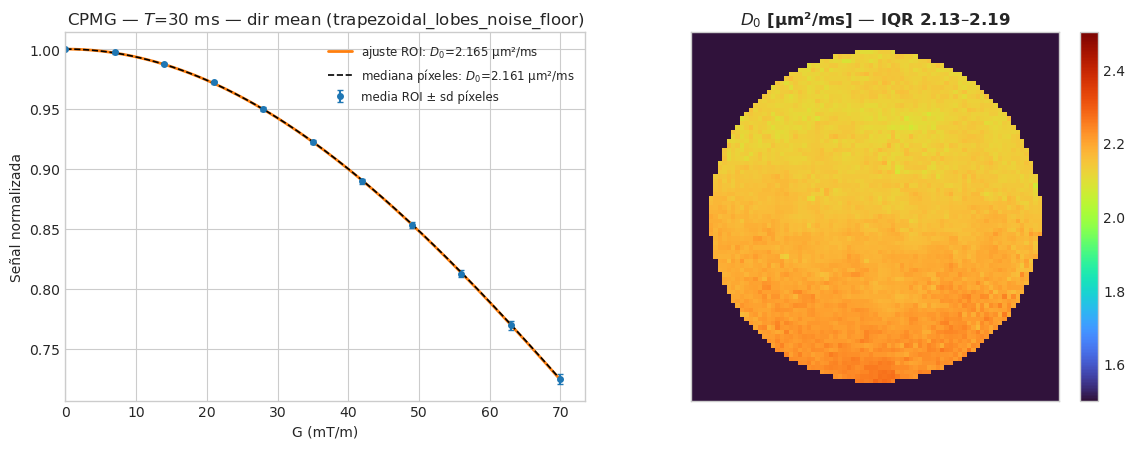

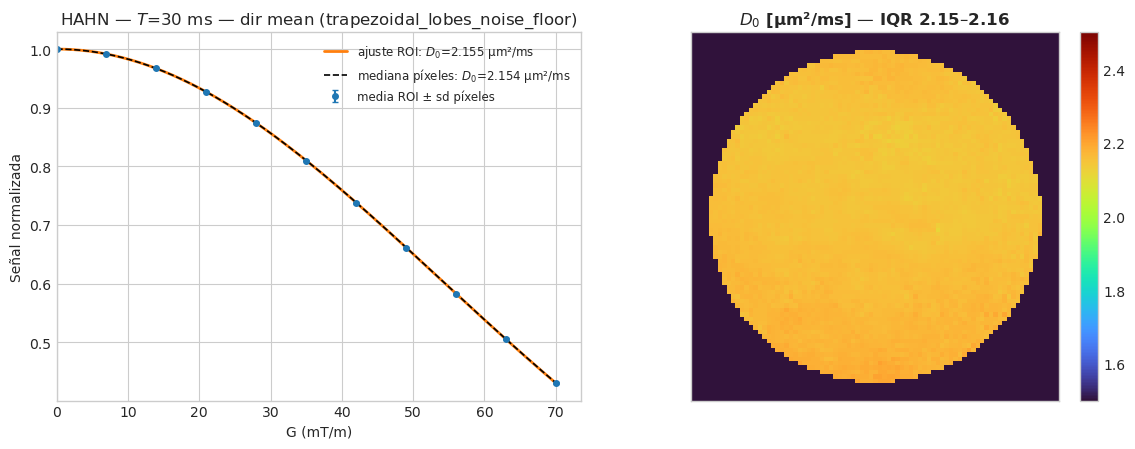

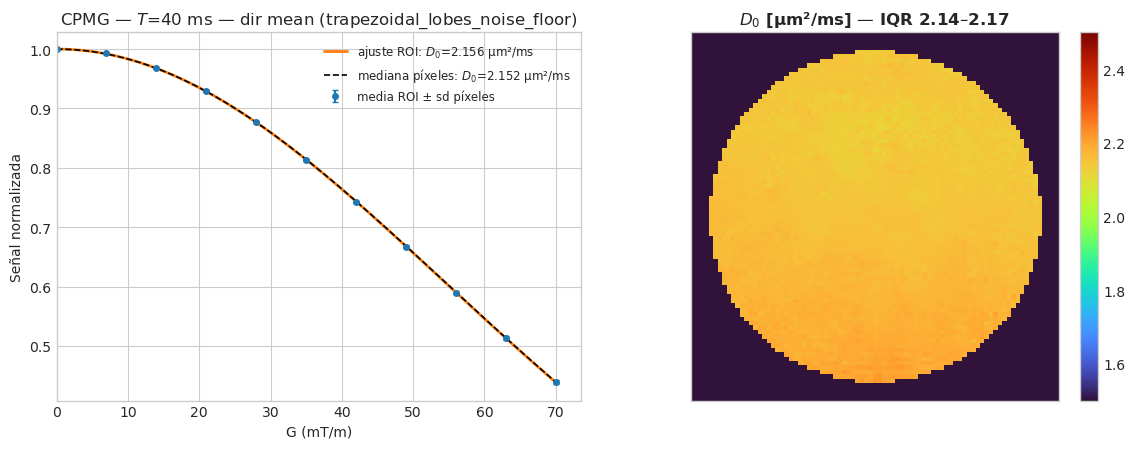

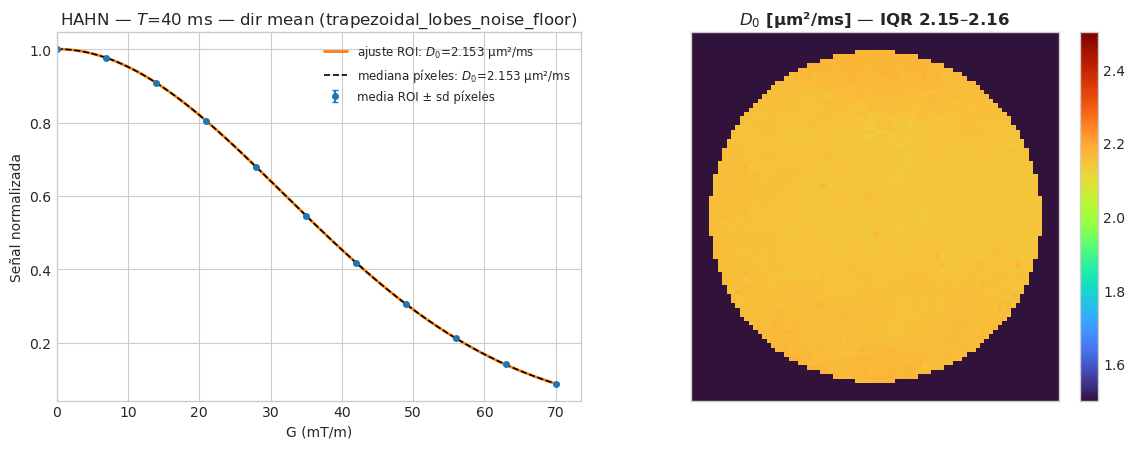

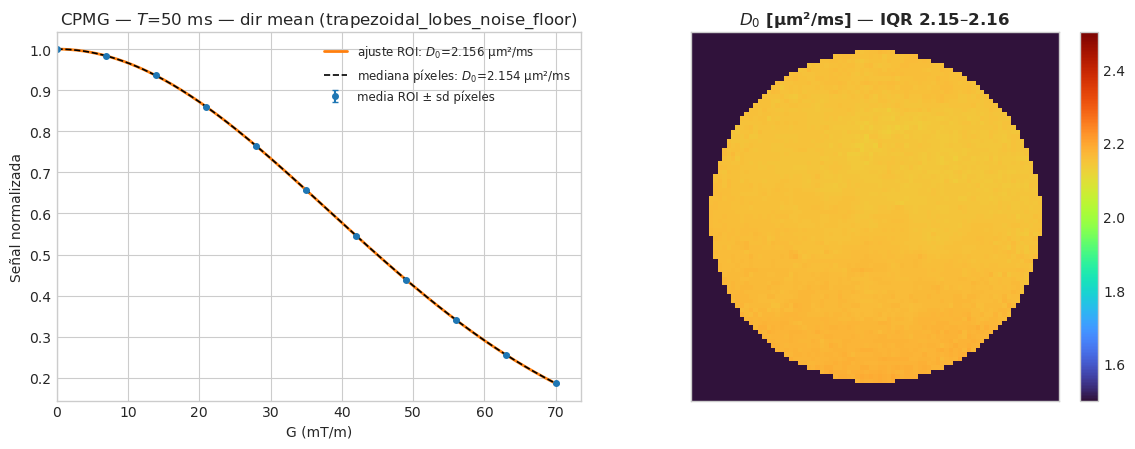

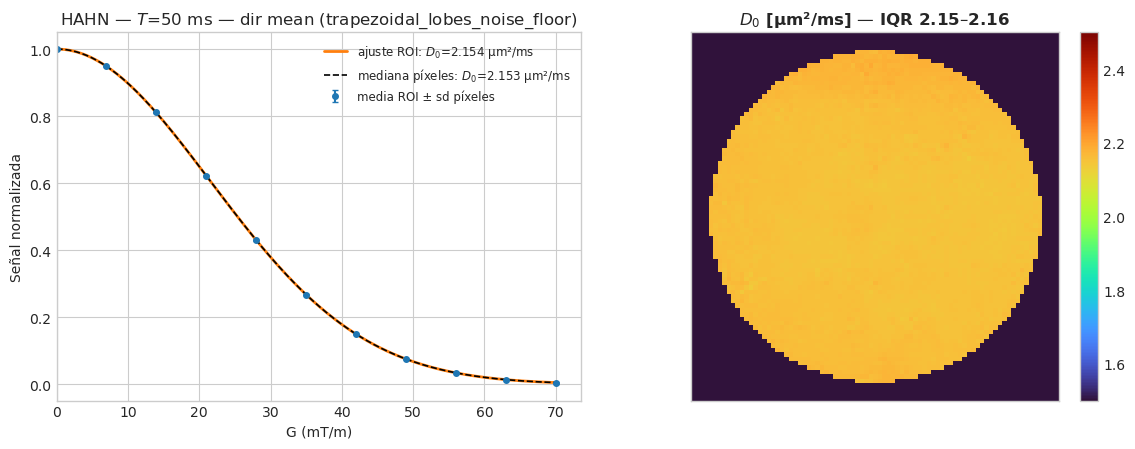

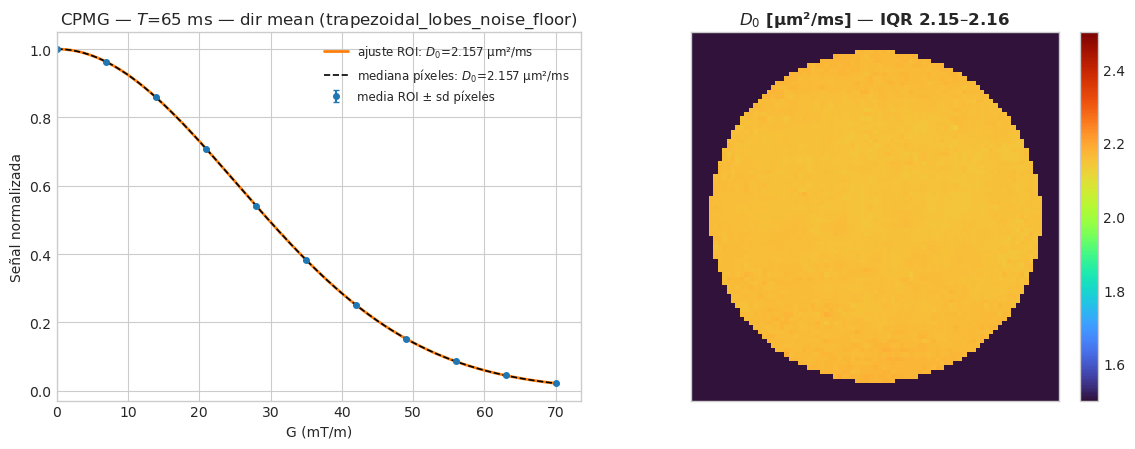

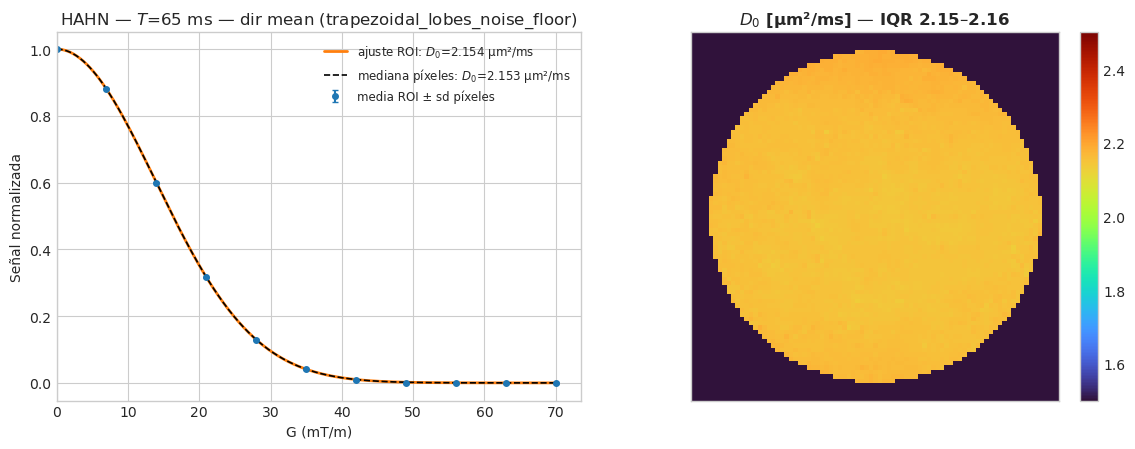

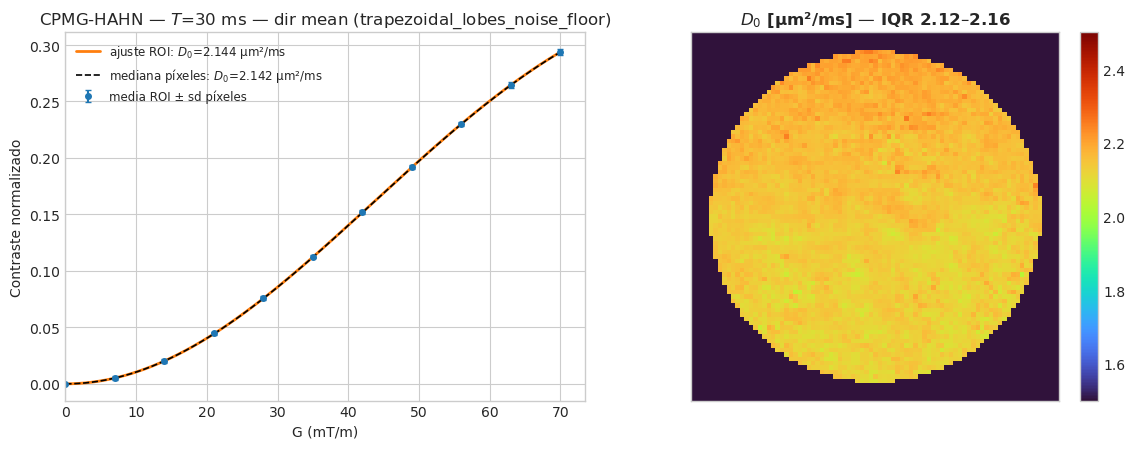

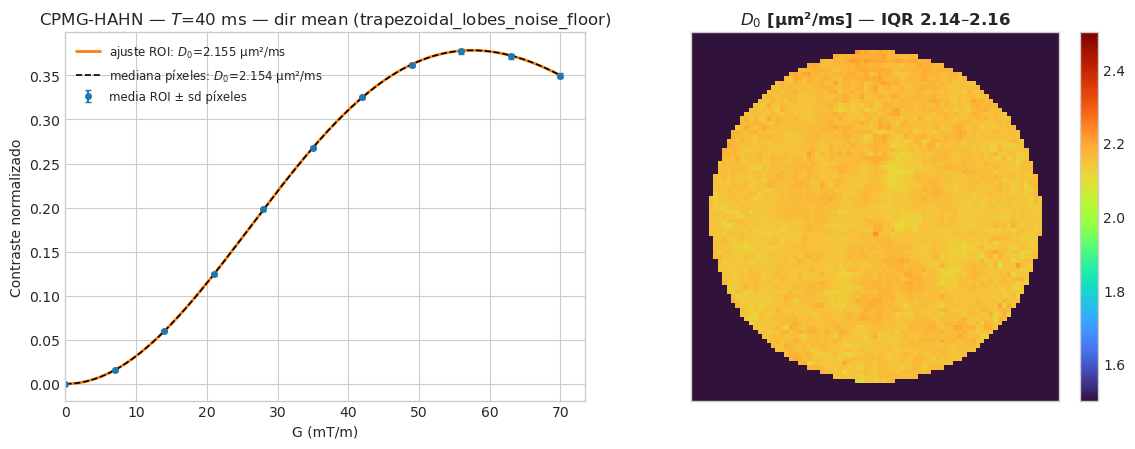

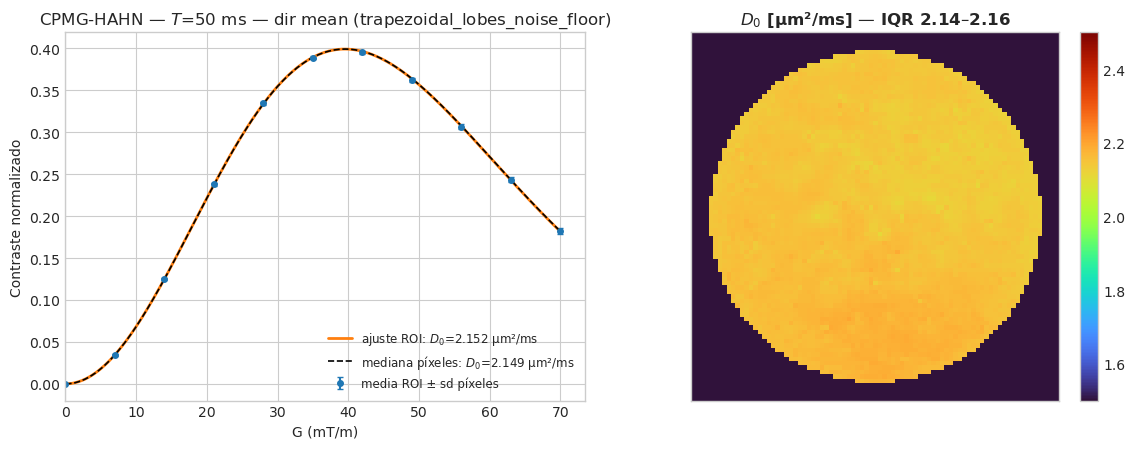

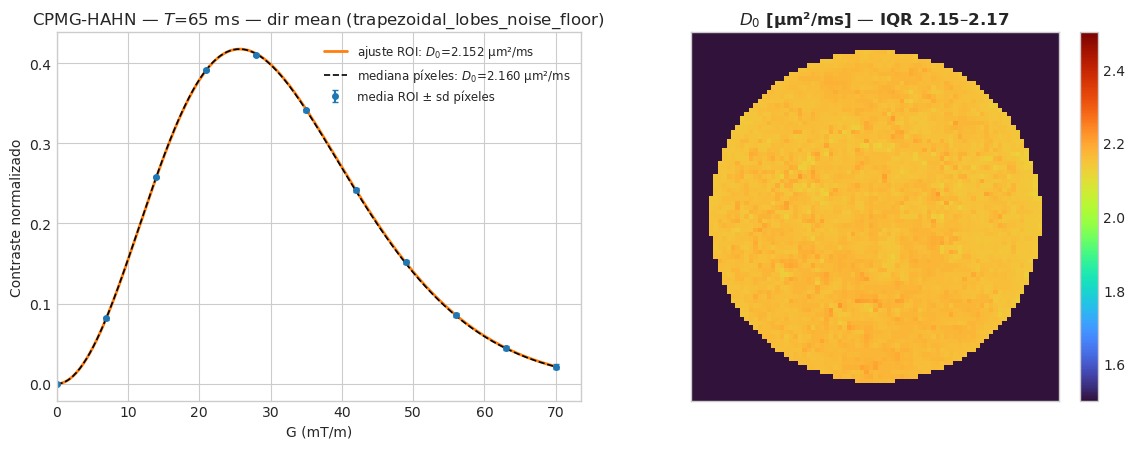

In [11]:
cmap = plt.get_cmap('turbo').copy()
cmap.set_bad(cmap(0.0))

union = np.any([r['_mask'] for r in results], axis=0)
if CROP_MARGIN is None:
    box = (slice(None), slice(None))
else:
    rows_idx, cols_idx = np.where(union)
    box = (slice(max(rows_idx.min() - CROP_MARGIN, 0), rows_idx.max() + CROP_MARGIN + 1),
           slice(max(cols_idx.min() - CROP_MARGIN, 0), cols_idx.max() + CROP_MARGIN + 1))


def show_map(ax, image):
    image = np.rot90(image[box], ROTATE_K)
    if FLIP_LR:
        image = image[:, ::-1]
    handle = ax.imshow(image, cmap=cmap, vmin=MAP_VMIN_UM2_MS, vmax=MAP_VMAX_UM2_MS, interpolation='nearest')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    return handle


def title_of(r):
    return f'{r["type"]} — $T$={r["td_ms"]:g} ms — dir {r["direction"]} ({OUTPUT_NAME})'


for r in [r for r in results if r['direction'] == PANEL_DIRECTION]:
    fig, (ax_curve, ax_map) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={'width_ratios': [1.0, 1.0]})
    g = r['_g']
    ax_curve.errorbar(g, r['_y_roi'], yerr=r['_y_sd'], fmt='o', ms=4, capsize=2, color='tab:blue',
                      label='media ROI ± sd píxeles')
    g_fine = np.linspace(0, g.max(), 300)
    ax_curve.plot(g_fine, r['_predict_fine'](g_fine, np.array([[r['D0_roi']]]))[0], color='tab:orange', lw=2,
                  label=f'ajuste ROI: $D_0$={r["D0_roi"]:.3f} µm²/ms')
    ax_curve.plot(g_fine, r['_predict_fine'](g_fine, np.array([[r['D0_median']]]))[0], color='k', lw=1.2, ls='--',
                  label=f'mediana píxeles: $D_0$={r["D0_median"]:.3f} µm²/ms')
    ax_curve.set(xlabel='G (mT/m)', ylabel='Contraste normalizado' if r['kind'] == 'contrast' else 'Señal normalizada',
                 title=title_of(r), xlim=(0, None))
    ax_curve.legend(fontsize=8.5)
    handle = show_map(ax_map, r['_maps']['d0'])
    ax_map.set_title(f'$D_0$ [µm²/ms] — IQR {r["D0_q25"]:.2f}–{r["D0_q75"]:.2f}', fontweight='bold')
    fig.colorbar(handle, ax=ax_map, fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'panel_{r["label"]}.png', dpi=180, bbox_inches='tight')
    plt.show()

## Todos los mapas: series × direcciones

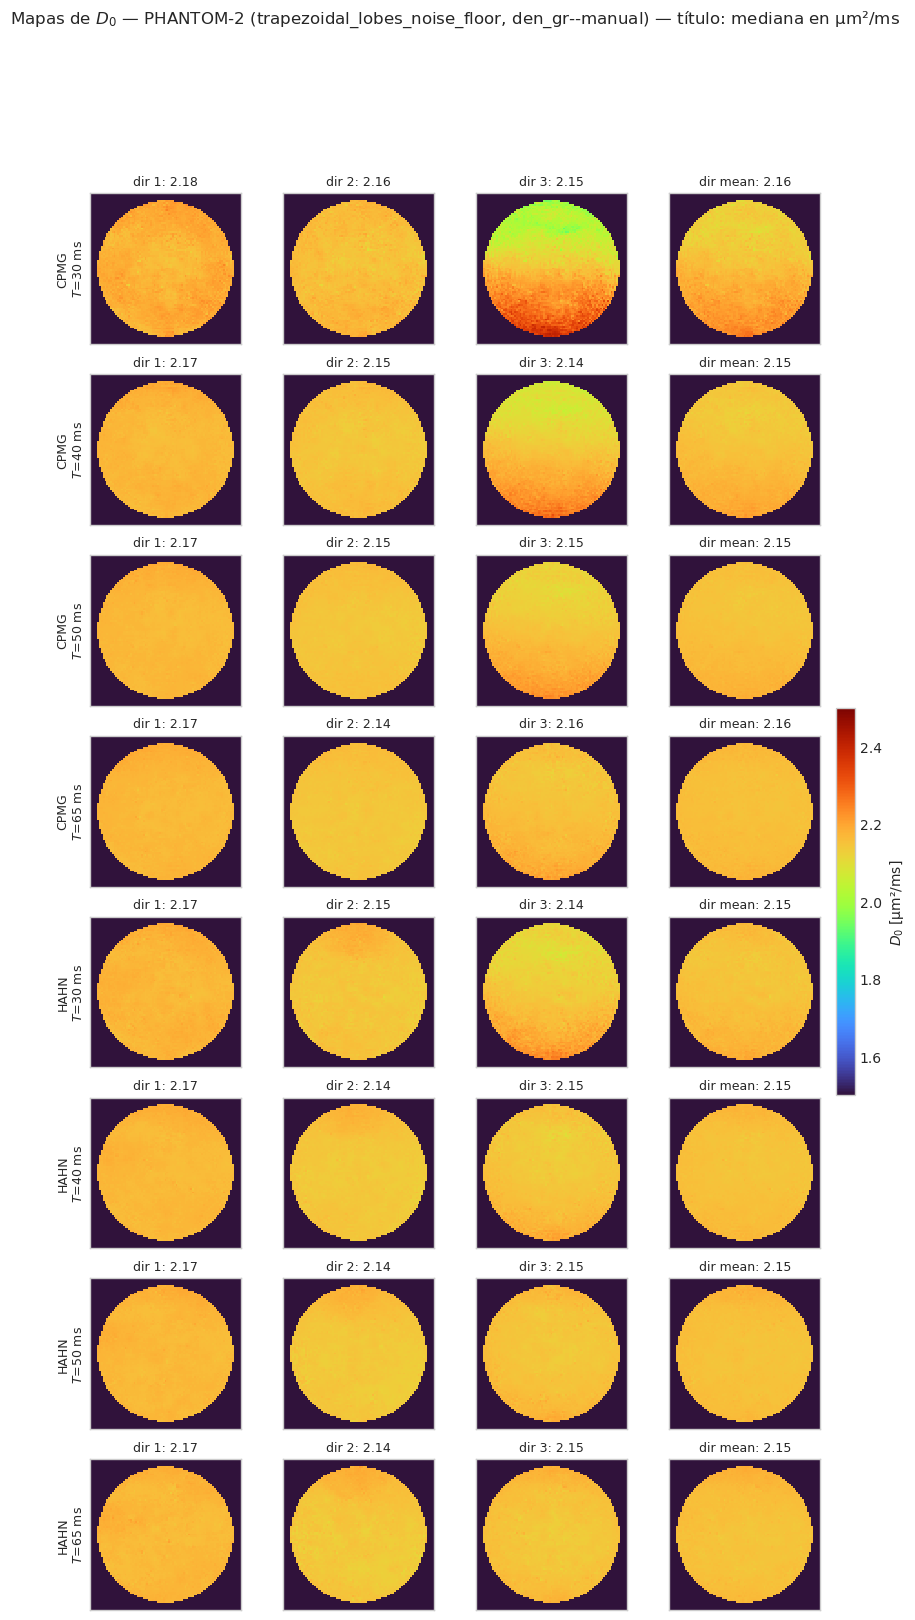

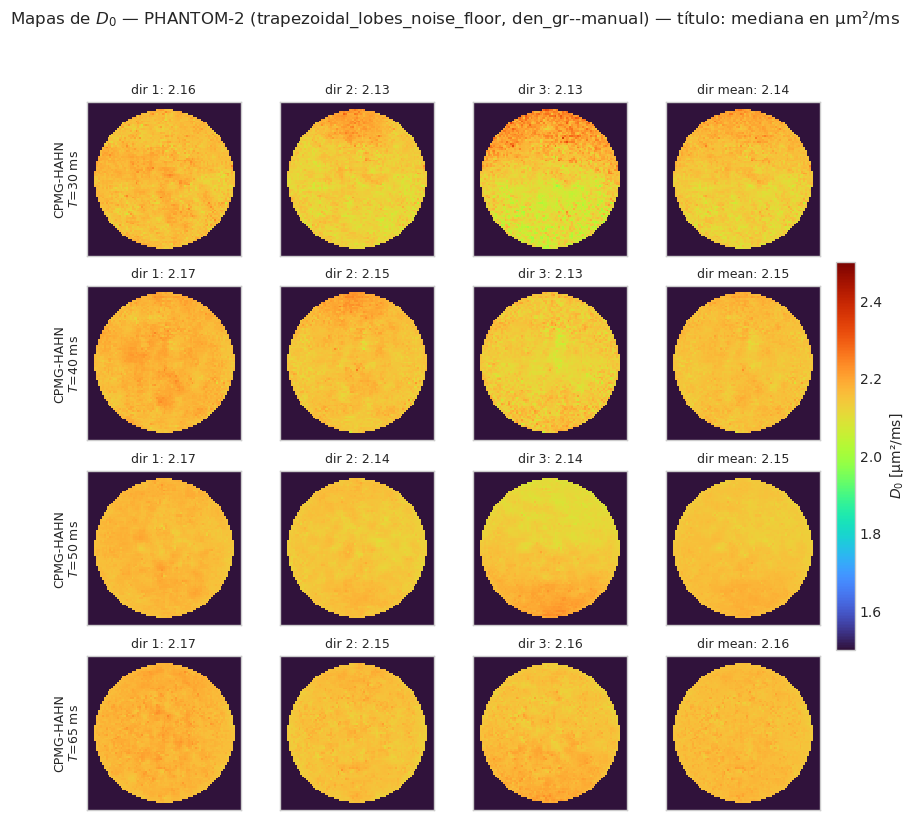

In [12]:
def map_grid(kind, stem):
    selected = [r for r in results if r['kind'] == kind]
    if not selected:
        return
    keys = sorted({(r['type'], r['td_ms']) for r in selected})
    fig, axes = plt.subplots(len(keys), len(DIRECTIONS), figsize=(2.3 * len(DIRECTIONS) + 0.8, 2.3 * len(keys)),
                             squeeze=False)
    for i, (sequence_type, td_ms) in enumerate(keys):
        for j, direction in enumerate(DIRECTIONS):
            r = next(r for r in selected if (r['type'], r['td_ms'], r['direction']) == (sequence_type, td_ms, direction))
            handle = show_map(axes[i, j], r['_maps']['d0'])
            axes[i, j].set_title(f'dir {direction}: {r["D0_median"]:.2f}', fontsize=9)
        axes[i, 0].set_ylabel(f'{sequence_type}\n$T$={td_ms:g} ms', fontsize=9)
    fig.colorbar(handle, ax=axes, fraction=0.025, pad=0.02, label='$D_0$ [µm²/ms]')
    fig.suptitle(f'Mapas de $D_0$ — {SUB} ({OUTPUT_NAME}, {ANALYSIS_TAG}) — título: mediana en µm²/ms')
    fig.savefig(FIGURE_DIR / f'{stem}.png', dpi=180, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{stem}.pdf', bbox_inches='tight')
    plt.show()


map_grid('signal', 'maps_signals')
map_grid('contrast', 'maps_contrasts')


## Floor map and $D_0$ maps with and without the correction

Top: $S_0$, floor map $F$ and $c=F/S_0$ (series of the longest $T$). Bottom: $D_0$ of the contrast at the two longest times, from the original notebook (if its NIfTI maps exist) and from this one. Without the correction the contrast maps at long $T$ copy the pattern of $c$: $D_0$ is overestimated where $S_0$ is lower.


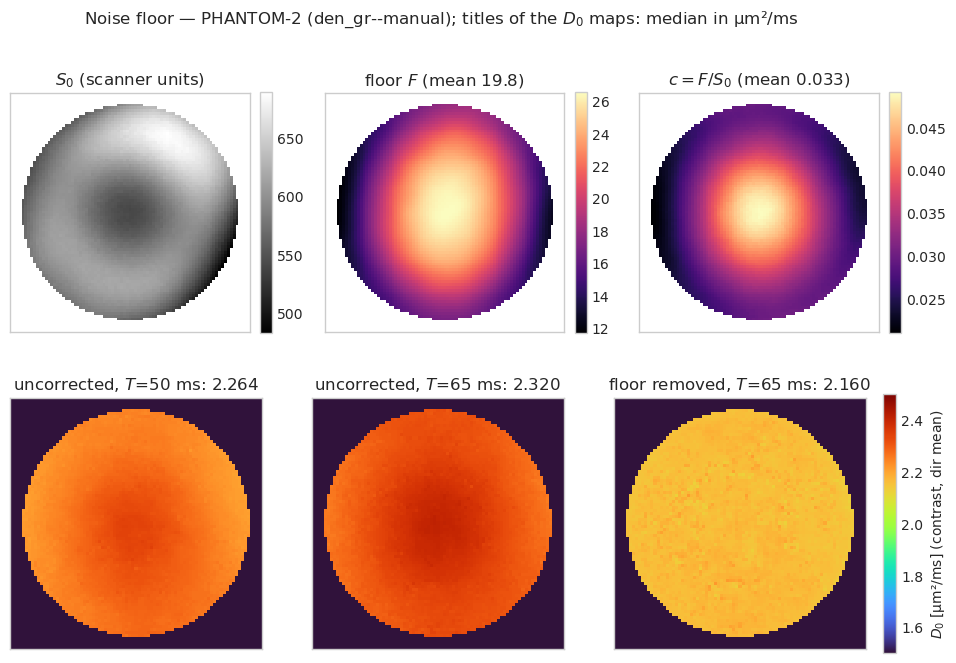

In [13]:

def oriented(image):
    image = np.rot90(image[box], ROTATE_K)
    return image[:, ::-1] if FLIP_LR else image


if NOISE_FLOOR:
    longest = max(series_data.values(), key=lambda sd: (sd['params']['TN'], sd['params']['type'] == 'HAHN'))
    s0_map = np.where(union_mask, longest['s0'], np.nan)
    original_dir = REPO_ROOT / 'results' / MODEL / f'sub-{SUB}' / 'pixel_maps' / ANALYSIS_TAG / 'nifti'
    contrast_rows = sorted([r for r in results if r['kind'] == 'contrast' and r['direction'] == PANEL_DIRECTION],
                           key=lambda r: r['td_ms'])[-2:]

    fig, axes = plt.subplots(2, 3, figsize=(11.5, 7.4))
    for ax, image, title, cm in ((axes[0, 0], s0_map, '$S_0$ (scanner units)', 'gray'),
                                 (axes[0, 1], FLOOR_MAP, f'floor $F$ (mean {floor_summary["F_roi"]:.1f})', 'magma'),
                                 (axes[0, 2], FLOOR_MAP / s0_map, f'$c=F/S_0$ (mean {floor_summary["c_roi"]:.3f})', 'magma')):
        handle = ax.imshow(oriented(image), cmap=cm, interpolation='nearest')
        ax.set_title(title)
        fig.colorbar(handle, ax=ax, fraction=0.046, pad=0.04)
    for ax, r in zip(axes[1, :2], contrast_rows):
        path = original_dir / f'D0_{r["label"]}.nii.gz'
        if path.exists():
            before = np.squeeze(np.asarray(nib.load(path).dataobj, dtype=float))
            handle = show_map(ax, before)
            ax.set_title(f'uncorrected, $T$={r["td_ms"]:g} ms: {np.nanmedian(before):.3f}')
        else:
            ax.set_title(f'{path.name} not found')
    handle = show_map(axes[1, 2], contrast_rows[-1]['_maps']['d0'])
    axes[1, 2].set_title(f'floor removed, $T$={contrast_rows[-1]["td_ms"]:g} ms: {contrast_rows[-1]["D0_median"]:.3f}')
    fig.colorbar(handle, ax=axes[1, :], fraction=0.02, pad=0.02, label='$D_0$ [µm²/ms] (contrast, dir mean)')
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    fig.suptitle(f'Noise floor — {SUB} ({ANALYSIS_TAG}); titles of the $D_0$ maps: median in µm²/ms')
    fig.savefig(FIGURE_DIR / 'noise_floor_maps.png', dpi=180, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / 'noise_floor_maps.pdf', bbox_inches='tight')
    plt.show()


## Distribución de $D_0$ y $D_0$ vs $T$

Histogramas de $D_0$ dentro de la máscara (dirección `PANEL_DIRECTION`) y mediana ± IQR en función de $T$; las cruces son el ajuste de la curva media del ROI. Para difusión libre $D_0$ no debería depender de $T$ ni del tipo de modulación.

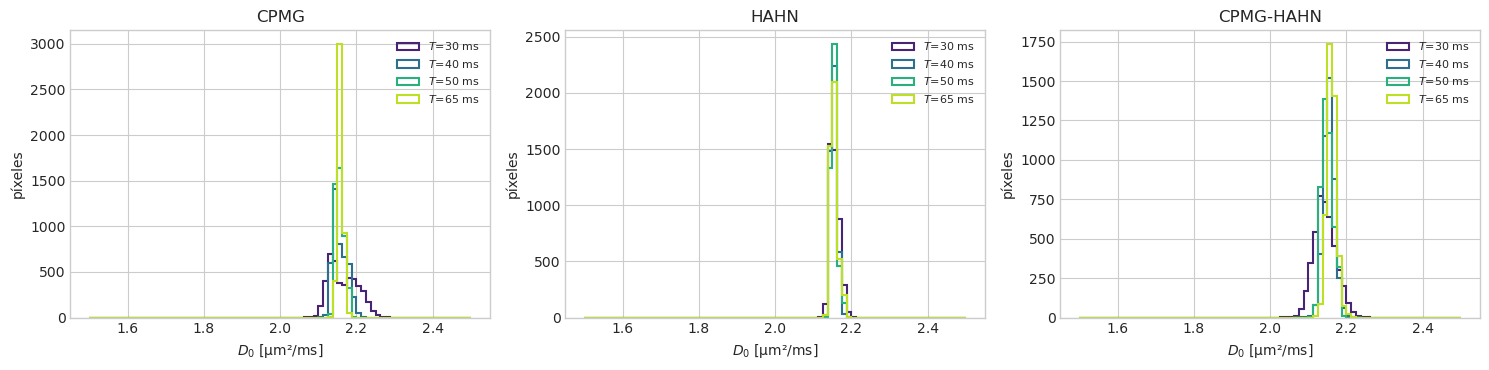

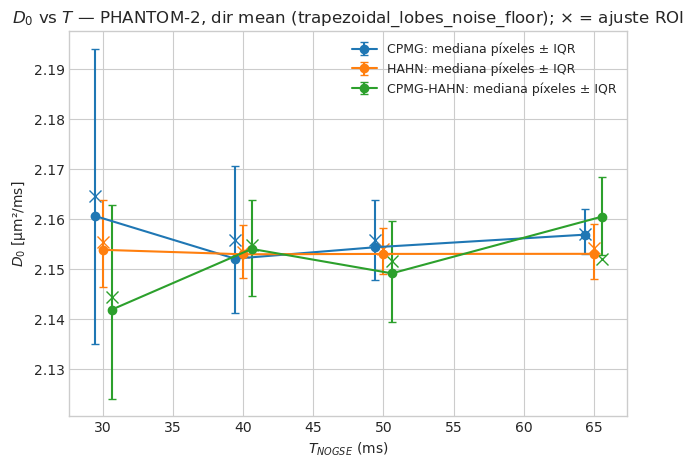

In [14]:
panel = [r for r in results if r['direction'] == PANEL_DIRECTION]
types = [t for t in ('CPMG', 'HAHN', 'CPMG-HAHN') if any(r['type'] == t for r in panel)]
times = sorted({r['td_ms'] for r in panel})
time_colors = dict(zip(times, plt.cm.viridis(np.linspace(0.1, 0.9, len(times)))))

fig, axes = plt.subplots(1, len(types), figsize=(5.0 * len(types), 3.8), squeeze=False, sharex=True)
for ax, sequence_type in zip(axes[0], types):
    for r in [r for r in panel if r['type'] == sequence_type]:
        d0 = r['_maps']['d0'][np.isfinite(r['_maps']['d0'])]
        ax.hist(d0, bins=80, range=(MAP_VMIN_UM2_MS, MAP_VMAX_UM2_MS), histtype='step', lw=1.5, color=time_colors[r['td_ms']],
                label=f'$T$={r["td_ms"]:g} ms')
    ax.set(title=sequence_type, xlabel='$D_0$ [µm²/ms]', ylabel='píxeles')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f'histograms_dir-{PANEL_DIRECTION}.png', dpi=180, bbox_inches='tight')
plt.show()

type_colors = {'CPMG': 'tab:blue', 'HAHN': 'tab:orange', 'CPMG-HAHN': 'tab:green'}
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for offset, sequence_type in zip(np.linspace(-0.6, 0.6, len(types)), types):
    rows = sorted([r for r in panel if r['type'] == sequence_type], key=lambda r: r['td_ms'])
    t = np.array([r['td_ms'] for r in rows]) + offset
    median = np.array([r['D0_median'] for r in rows])
    yerr = [median - [r['D0_q25'] for r in rows], [r['D0_q75'] for r in rows] - median]
    ax.errorbar(t, median, yerr=yerr, fmt='o-', capsize=3, color=type_colors[sequence_type],
                label=f'{sequence_type}: mediana píxeles ± IQR')
    ax.plot(t, [r['D0_roi'] for r in rows], 'x', ms=8, color=type_colors[sequence_type])
ax.set(xlabel='$T_{NOGSE}$ (ms)', ylabel='$D_0$ [µm²/ms]', title=f'$D_0$ vs $T$ — {SUB}, dir {PANEL_DIRECTION} ({OUTPUT_NAME}); × = ajuste ROI')
ax.legend(fontsize=9)
fig.savefig(FIGURE_DIR / f'D0_vs_T_dir-{PANEL_DIRECTION}.png', dpi=180, bbox_inches='tight')
plt.show()

## Comparación con los ajustes de ROI de los otros notebooks

Si `nogse_fits_<MODEL>.ipynb` ya se ejecutó, se comparan sus $D_0$ (ROI `water`, mm²/s → µm²/ms) con el ajuste de la curva media de este notebook (`D0_roi`, debe coincidir si la máscara es la misma) y con la mediana de los píxeles. `roi_vs_master_max_abs` es la diferencia máxima entre la curva del ROI calculada aquí y `value_norm` del master.

In [15]:
roi_tables = REPO_ROOT / 'results' / OUTPUT_NAME / f'sub-{SUB}' / 'tables'  # noise floor
for name, kind in (('signal_fits.csv', 'signal'), ('contrast_fits.csv', 'contrast')):
    path = roi_tables / name
    if MODEL == 'bval' or not path.exists():
        print(f'{path} no existe: ejecutar nogse_fits_{OUTPUT_NAME}.ipynb para comparar.')
        continue
    roi_fits = pd.read_csv(path, dtype={'direction': str})
    if 'correction' in roi_fits:  # noise floor: tables of nogse_fits_trapezoidal_lobes_noise_floor.ipynb
        roi_fits = roi_fits.loc[roi_fits['correction'].eq('floor_removed' if NOISE_FLOOR else 'uncorrected')]
    roi_fits['D0_roi_notebook'] = roi_fits['D0_mm2_s'] / UM2_MS_TO_MM2_S
    on = ['type', 'td_ms', 'direction'] if kind == 'signal' else ['td_ms', 'direction']
    this = summary.loc[summary['kind'].eq(kind), on + ['D0_roi', 'D0_median', 'roi_vs_master_max_abs']]
    merged = this.merge(roi_fits[on + ['D0_roi_notebook']], on=on)
    merged['D0_roi / notebook'] = merged['D0_roi'] / merged['D0_roi_notebook']
    merged['D0_median / notebook'] = merged['D0_median'] / merged['D0_roi_notebook']
    print(name)
    display(merged)
print('Mapas NIfTI en:', NIFTI_DIR)
print('Figuras en:', FIGURE_DIR)

signal_fits.csv


,type,td_ms,direction,D0_roi,D0_median,roi_vs_master_max_abs,D0_roi_notebook,D0_roi / notebook,D0_median / notebook
0,CPMG,30.0,1,2.183751,2.184787,0.000000e+00,2.183744,1.000003,1.000478
1,CPMG,30.0,2,2.159810,2.159843,1.110223e-16,2.159803,1.000003,1.000019
2,CPMG,30.0,3,2.149979,2.149107,1.110223e-16,2.149972,1.000003,0.999598
3,HAHN,30.0,1,2.173310,2.173365,2.220446e-16,2.173303,1.000003,1.000029
4,HAHN,30.0,2,2.148360,2.145432,2.220446e-16,2.148353,1.000003,0.998640
5,HAHN,30.0,3,2.144728,2.138042,3.330669e-16,2.144721,1.000003,0.996886
6,CPMG,40.0,1,2.170526,2.170277,1.110223e-16,2.170519,1.000003,0.999888
7,CPMG,40.0,2,2.149058,2.148651,1.665335e-16,2.149051,1.000003,0.999814
8,CPMG,40.0,3,2.147564,2.144297,1.110223e-16,2.147557,1.000003,0.998482
9,HAHN,40.0,1,2.168497,2.168435,1.110223e-16,2.168472,1.000011,0.999983


contrast_fits.csv


,td_ms,direction,D0_roi,D0_median,roi_vs_master_max_abs,D0_roi_notebook,D0_roi / notebook,D0_median / notebook
0,30.0,1,2.160406,2.160968,NaN,2.160392,1.000006,1.000266
1,30.0,2,2.136108,2.131532,NaN,2.136095,1.000006,0.997864
2,30.0,3,2.136600,2.130474,NaN,2.136587,1.000006,0.997139
3,40.0,1,2.173401,2.172978,NaN,2.173423,0.999990,0.999796
4,40.0,2,2.156881,2.153373,NaN,2.156900,0.999991,0.998365
5,40.0,3,2.134513,2.133066,NaN,2.134530,0.999992,0.999314
6,50.0,1,2.167023,2.165953,NaN,2.167675,0.999699,0.999206
7,50.0,2,2.146663,2.144841,NaN,2.147284,0.999711,0.998862
8,50.0,3,2.140936,2.136615,NaN,2.141502,0.999736,0.997718
9,65.0,1,2.163893,2.174425,NaN,2.164451,0.999742,1.004608


Mapas NIfTI en: /tmp/claude-1000/-mnt-c-Users-ignacio-docs-GitHub/d9129f11-fb21-48b5-ab45-073f5631db32/scratchpad/proj/repos/signal_analysis/results/trapezoidal_lobes_noise_floor/sub-PHANTOM-2/pixel_maps/den_gr--manual/nifti
Figuras en: /tmp/claude-1000/-mnt-c-Users-ignacio-docs-GitHub/d9129f11-fb21-48b5-ab45-073f5631db32/scratchpad/proj/repos/signal_analysis/results/trapezoidal_lobes_noise_floor/sub-PHANTOM-2/pixel_maps/den_gr--manual/figures
